<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/04_%E7%89%B9%E5%BE%B5%E5%B7%A5%E7%A8%8B/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. 特徵工程 (Feature Engineering)

特徵工程決定了演算法的學習上限。本範例透過「顧客消費資料集」示範：
1. **特徵縮放**：`StandardScaler`（標準化）與 `MinMaxScaler`（歸一化）。
2. **類別編碼**：`One-Hot Encoding` 獨熱編碼。
3. **Seaborn 視覺化**：繪製縮放前後的數據分佈箱形圖。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 讀取顧客消費資料集
df = pd.read_csv('顧客消費資料集.csv')
print("=== 原始顧客資料 ===")
display(df.head())


=== 原始顧客資料 ===


,年齡,年消費額_元,會員等級,所在縣市
0,22,36000,銅卡,台北市
1,28,52000,白金,新北市
2,35,85000,鑽石,台中市
3,45,120000,白金,高雄市
4,58,180000,鑽石,台北市


In [4]:
# 1. 數值特徵縮放
num_cols = ['年齡', '年消費額_元']

# 標準化 (Z-Score)
std_scaler = StandardScaler()
df_std = pd.DataFrame(std_scaler.fit_transform(df[num_cols]), columns=['年齡_標準化', '年消費額_標準化'])

# 歸一化 (0~1)
minmax_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(minmax_scaler.fit_transform(df[num_cols]), columns=['年齡_歸一化', '年消費額_歸一化'])

print("=== 標準化後數據 (平均約0, 標準差約1) ===")
print(df_std.head().round(2))

print("\n=== 歸一化後數據 (壓縮至 0 ~ 1) ===")
print(df_minmax.head().round(2))


=== 標準化後數據 (平均約0, 標準差約1) ===
   年齡_標準化  年消費額_標準化
0   -1.44     -1.30
1   -0.96     -1.01
2   -0.39     -0.39
3    0.43      0.26
4    1.49      1.38

=== 歸一化後數據 (壓縮至 0 ~ 1) ===
   年齡_歸一化  年消費額_歸一化
0    0.00      0.00
1    0.16      0.09
2    0.34      0.28
3    0.61      0.48
4    0.95      0.83


In [5]:
# 2. 獨熱編碼 (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['會員等級', '所在縣市'], prefix=['等級', '縣市'])
print("=== 獨熱編碼後的新欄位 ===")
print(df_encoded.columns.tolist())
display(df_encoded.head(3))


=== 獨熱編碼後的新欄位 ===
['年齡', '年消費額_元', '等級_白金', '等級_銅卡', '等級_鑽石', '縣市_台中市', '縣市_台北市', '縣市_新北市', '縣市_高雄市']


,年齡,年消費額_元,等級_白金,等級_銅卡,等級_鑽石,縣市_台中市,縣市_台北市,縣市_新北市,縣市_高雄市
0,22,36000,False,True,False,False,True,False,False
1,28,52000,True,False,False,False,False,True,False
2,35,85000,False,False,True,True,False,False,False


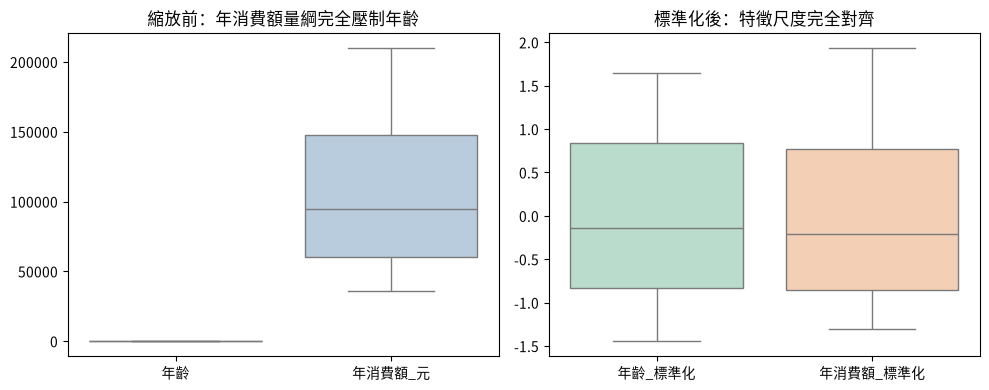

💡 觀念總結：特徵縮放避免大數值特徵主宰距離計算，獨熱編碼讓文字類別轉為模型可計算的向量！


In [6]:
# 3. 視覺化箱形圖對比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(ax=axes[0], data=df[num_cols], palette='Pastel1')
axes[0].set_title('縮放前：年消費額量綱完全壓制年齡', fontsize=12)

sns.boxplot(ax=axes[1], data=df_std, palette='Pastel2')
axes[1].set_title('標準化後：特徵尺度完全對齊', fontsize=12)

plt.tight_layout()
plt.show()

print("💡 觀念總結：特徵縮放避免大數值特徵主宰距離計算，獨熱編碼讓文字類別轉為模型可計算的向量！")
